# **MVP — Predição de Doença Cardíaca com Machine Learning**
## Sistema de Apoio à Triagem Cardiovascular (Predição de Doença Cardíaca)
### **Pós-Graduação em Engenharia de Software — PUC-Rio** **Disciplina:** Engenharia de Sistemas de Software Inteligentes, **Aluna:** Elaine Cristina Bundscherer, **Repositório:** github.com/Elainecbr/mvp-predicao-cardiaca



---



### **Projeto Sistema inteligente de apoio à triagem médica preventiva - Predição de Insuficiência Cardíaca**
# Sistema Inteligente de Apoio à Triagem Cardiovascular (Predição de Doença Cardíaca)
**Disciplina:** Engenharia de Sistemas de Software Inteligentes — PUC-Rio

## **1. Definição do Problema, Motivação, Objetivo e Metodologia**
Este projeto aplica aprendizado de máquina supervisionado (**Classificação Binária**) para identificar pacientes com alto risco de desenvolver doença cardíaca, analisando 11 variáveis clínicas para prever o risco de insuficiência/doença cardíaca (`HeartDisease`: `0` = Baixo Risco, `1` = Alto Risco). A partir destes 11 indicadores clínicos reais (incluindo pressão arterial em repouso, colesterol e eletrocardiograma), pode auxiliar como ferramenta na prevenção precoce.

Assim sendo, o sistema funciona como uma **ferramenta de triagem clínica preventiva**: o usuário preenche os dados de exames no formulário e a API classifica o paciente em duas categorias possíveis (`0` ou `1`).


> **Importante: Estas informações têm caráter meramente informativo. Para aconselhamento médico ou diagnóstico, consulte um especialista.**

## **1.2 Motivação:**

As doenças cardiovasculares (DCVs) são a principal causa de morte em todo o mundo, ceifando cerca de 17,9 milhões de vidas anualmente — o que corresponde a 31% de todos os óbitos globalmente. Quatro em cada cinco mortes por DCV decorrem de infartos e acidentes vasculares cerebrais (AVCs), sendo que um terço desses óbitos ocorre de forma prematura em pessoas com menos de 70 anos. A insuficiência cardíaca é uma condição comum resultante de DCVs. Este conjunto de dados contém 11 variáveis ​​que podem ser utilizadas para prever a possível presença de uma doença cardíaca.

*Fonte do texto: "https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction"*



## **1.2.1 Origem dos Dados:**
Arquivo Dataset - Heart Failure Prediction Dataset - heart.csv - baixado de kaggle
Donor:
David W. Aha (aha '@' ics.uci.edu) (714) 856-8779

https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction/download?datasetVersionNumber=1

## **1.2.2 O Dataset**
**Heart Failure Prediction Dataset**
que combina 5 bases clínicas independentes (Cleveland, Hungria, Suíça, Long Beach e Stattlog), totalizando **918 pacientes reais** após remoção de duplicatas. O arquivo foi hospedado no repositório público do GitHub deste projeto e é carregado via **URL pública**, permitindo a execução direta deste notebook sem nenhuma configuração.

| Atributo | Descrição | Tipo |
|---|---|---|
| `Age` | Idade do paciente (anos) | Numérico |
| `Sex` | Sexo (M / F) | Categórico |
| `ChestPainType` | Tipo de dor torácica (TA: angina típica, ATA: atípica, NAP: dor não anginosa, ASY: assintomático) | Categórico |
| `RestingBP` | Pressão arterial em repouso (mmHg) | Numérico |
| `Cholesterol` | Colesterol sérico (mg/dl) | Numérico |
| `FastingBS` | Glicemia de jejum > 120 mg/dl (1: sim, 0: não) | Binário |
| `RestingECG` | Eletrocardiograma em repouso (Normal, ST: anormalidade ST-T, LVH: hipertrofia ventricular esquerda) | Categórico |
| `MaxHR` | Frequência cardíaca máxima atingida | Numérico |
| `ExerciseAngina` | Angina induzida por exercício (Y / N) | Categórico |
| `Oldpeak` | Depressão do segmento ST induzida por exercício | Numérico |
| `ST_Slope` | Inclinação do segmento ST no pico do exercício (Up, Flat, Down) | Categórico |
| `HeartDisease` | **Classe alvo** (1: doença cardíaca, 0: normal) | Binário |

## **1.5 Objetivo: O Que o Sistema Vai Analisar e Predizer na Prática?**

**As Entradas (O que o modelo analisa no formulário):**

O modelo avalia simultaneamente os indicadores clínicos reais do paciente:
	1. Idade (Age)
  2. Sexo (Sex)
	3. Tipo de Dor no Peito (ChestPainType)
	4. Pressão Arterial em Repouso (RestingBP em mmHg)
	5. Colesterol Sérico (Cholesterol em mg/dl)
	6. Glicemia em Jejum (FastingBS > 120 mg/dl)
	7. Eletrocardiograma em Repouso (RestingECG)
	8. Frequência Cardíaca Máxima (MaxHR)
	9. Angina Induzida por Exercício (ExerciseAngina)
	10. Depressão do Segmento ST (Oldpeak) e Inclinação ST (ST_Slope)
  11. Inclinação do segmento ST no pico do exercício (Up, Flat, Down)

**A Saída (O que a API prediz — Coluna HeartDisease):**
- 0 (Baixo Risco / Normal): O perfil clínico do paciente não apresenta padrões associados a doença cardíaca.

- 1 (Alto Risco / Alerta): O paciente apresenta combinação de fatores (como pressão arterial elevada, colesterol alto, angina ou alterações no ECG) fortemente associada a doença cardíaca / risco cardiovascular (como insuficiência cardíaca ou infarto).

### **1.6 Metodologia**

Seguiremos o fluxo clássico de experimentação em Machine Learning estudado na disciplina:

1. **Carga dos dados** via URL pública e análise exploratória;
2. **Pré-processamento** (codificação de variáveis categóricas);
3. **Holdout estratificado** (80% treino / 20% teste);
4. **Modelagem** com validação cruzada 10-fold comparando **KNN, Árvore de Classificação (CART), Naive Bayes e SVM** (além do Random Forest como *ensemble* adicional), em três cenários: dados **originais**, **padronizados** (`StandardScaler`) e **normalizados** (`MinMaxScaler`), usando **Pipelines** para evitar vazamento de dados (*data leakage*);
5. **Otimização de hiperparâmetros** com `GridSearchCV`;
6. **Avaliação final** na base de teste e **exportação do modelo** para uso embarcado na aplicação full stack (API Flask).






---



**2. Célula de Código — Importações - Importação das Bibliotecas**

Todas as importações são feitas no início do notebook, seguindo as boas
práticas de codificação vistas na disciplina de Programação Orientada a Objetos. Utilizamos
 Python com a biblioteca Scikit-Learn (obrigatória), além de pandas/numpy para manipulação de
 dados, matplotlib para visualização e pickle para a serialização do modelo final. Mais informações veja nos comentários.

In [ ]:
# Configuração para não exibir avisos (warnings)
import warnings
warnings.filterwarnings("ignore")

# ======================================================================================================
# Importações - Importação das Bibliotecas
# ======================================================================================================

# Manipulação de dados, visualização e serialização
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
# Divisão de dados, validação cruzada, otimização e pipelines (Scikit-Learn)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
# Algoritmos clássicos de classificação
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier



**3. Célula de Código — Carga do Dataset**

Carga do Dataset via URL Pública

O arquivo heart.csv está hospedado no repositório público deste projeto no GitHub e é lido diretamente pela sua URL raw, sem necessidade de upload manual ou qualquer configuração.
Este trecho de código é o ponto de partida clássico de um projeto de Ciência de Dados ou Machine Learning em Python. O objetivo principal dele é buscar uma tabela de dados na internet, carregá-la na memória do computador e fazer uma verificação inicial para confirmar se tudo veio corretamente.
Para que esse código funcione, ele depende de uma biblioteca fundamental chamada Pandas (geralmente importada antes como import pandas as pd), que funciona como um "Excel turbinado" dentro do Python.

In [ ]:

# ======================================================================================================
# Carga do dataset
# ======================================================================================================
# Carga do dataset via URL pública do GitHub
# Cria uma variável chamada url e guarda endereço eletrônico exato onde o arquivo heart.csv está hospedado.

url = "https://raw.githubusercontent.com/Elainecbr/mvp-predicao-cardiaca/refs/heads/main/heart.csv"

# ======================================================================================================
# Lendo e estruturando os dados
# ======================================================================================================
#a função read_csv() da biblioteca Pandas (pd) para acessar o link guardado na variável url, baixar o conteúdo
# e transformá-lo em uma tabela chamada DataFrame. Essa tabela pronta é salva na variável dataset.

dataset = pd.read_csv(url)

# ======================================================================================================
# Confirmando o carregamento e o tamanho da tabela
# ======================================================================================================
print(f"Dataset carregado com sucesso! Dimensões: {dataset.shape}")

# ======================================================================================================
#  Mostrando os primeiros registros - pega apenas as 5 primeiras linhas da tabela dataset.
#  A função display() renderiza essas linhas na tela em um formato visual de tabela bem formatada
# ======================================================================================================
display(dataset.head())

Dataset carregado com sucesso! Dimensões: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


**3.1 Célula de Código - Análise Exploratória**

Antes de modelar, precisamos conhecer os dados: tipos das colunas, estatísticas descritivas, existência de valores nulos e a distribuição da classe alvo.

**dataset.info()**

Na etapa de Análise Exploratória de Dados (EDA), o comando dataset.info() da biblioteca Pandas é o primeiro "raio-X" da sua tabela. Ele gera um resumo técnico rápido sobre a estrutura do conjunto de dados.

In [ ]:
# Informações gerais: tipos de dados e valores não nulos
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


**dataset.describe()**

O comando dataset.describe() da biblioteca Pandas é o próximo passo na Análise Exploratória de Dados (EDA) e gera um resumo estatístico completo das colunas numéricas do seu conjunto de dados. Enquanto o info() mostra a estrutura técnica da tabela, o describe() revela como os números estão distribuídos.

In [ ]:
# Estatísticas descritivas das variáveis numéricas
dataset.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


# Distribuição da classe alvo


**A análise da distribuição da classe alvo** verifica quantos exemplos existem para cada categoria que você deseja prever em um problema de classificação (como "Sim" vs. "Não" ou "Fraude" vs. "Legítimo"). **Essa etapa da Análise Exploratória** é fundamental para descobrir se os **dados estão equilibrados ou se há um desbalanceamento de classes.**

Esse código abaixo calcula, imprime e gera um gráfico de barras mostrando a proporção exata entre pacientes saudáveis (0) e pacientes com doença cardíaca (1) no seu conjunto de dados. Ele une o Pandas para fazer a matemática e o Matplotlib para construir a visualização final.

Realiza uma etapa essencial da Análise Exploratória de Dados (EDA): verificar o balanceamento da variável alvo, ou seja, contar quantos pacientes têm e quantos não têm doença cardíaca, exibindo esses números tanto em texto quanto em um gráfico de barras.


**Por que esse bloco é importante nesse projeto?**
Em problemas de classificação (como prever se um paciente está doente ou saudável), precisamos saber se os exemplos estão bem divididos. Se 99% dos pacientes fossem saudáveis e apenas 1% doentes, um modelo de Inteligência Artificial poderia "chutar" que todo mundo é saudável e acertar 99% das vezes, sem aprender nada de verdade. Esse código serve para diagnosticar se a base de dados é equilibrada antes de treinar o modelo.

Como estamos lidando com predição dediagnóstico médico (doença cardíaca), esse gráfico responde imediatamente se a base está equilibrada. Se houver muito menos pacientes doentes (1) do que saudáveis (0), será usar técnicas como stratify=y na divisão dos dados e priorizar a métrica Recall no Scikit-Learn, pois deixar a predição de um paciente doente passar sem diagnóstico (falso negativo) é muito mais grave do que um alarme falso.


Pacientes sem doença cardíaca (0): 410 (44.7%)
Pacientes com doença cardíaca (1): 508 (55.3%)


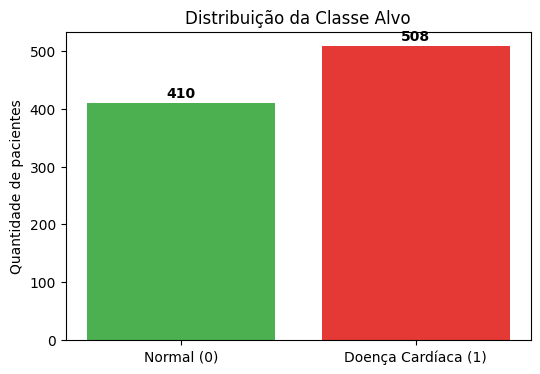

In [ ]:
# ======================================================================================================
# Distribuição da classe alvo (HeartDisease) -A cessa a coluna 'HeartDisease' da tabela.
# ======================================================================================================
# O método .value_counts() conta quantas vezes cada valor aparece (quantos 0 e quantos 1).
# O .sort_index() organiza o resultado em ordem crescente do índice (garantindo que o 0 venha primeiro e o 1 venha depois).

contagem = dataset['HeartDisease'].value_counts().sort_index()

# ======================================================================================================
# Calculando as porcentagens- • contagem da linha anterior, mas o parâmetro normalize=True transforma os
# números absolutos em proporções (entre 0 e 1, como 0.45 e 0.55). Multiplicar por 100 converte essas
# proporções em porcentagens reais (45.0 e 55.0).
# ======================================================================================================

percentual = dataset['HeartDisease'].value_counts(normalize=True).sort_index() * 100

# ======================================================================================================
# Exibindo o resumo em texto
# ======================================================================================================

print(f"Pacientes sem doença cardíaca (0): {contagem[0]} ({percentual[0]:.1f}%)")
print(f"Pacientes com doença cardíaca (1): {contagem[1]} ({percentual[1]:.1f}%)")

# ======================================================================================================
# Construção do Gráfico (Visualização com Matplotlib)
# ======================================================================================================

# Criando a tela de pintura - Definir o tamanho manualmente evita que o gráfico fique grande demais ou esmagado na tela.
fig, ax = plt.subplots(figsize=(6, 4))

# Adicionando título e rótulo
ax.bar(['Normal (0)', 'Doença Cardíaca (1)'], contagem.values, color=['#4caf50', '#e53935'])
ax.set_title('Distribuição da Classe Alvo')
ax.set_ylabel('Quantidade de pacientes')

# Escrevendo os números em cima das barras
for i, v in enumerate(contagem.values):
    ax.text(i, v + 10, str(v), ha='center', fontweight='bold')

# Mostrando o resultado final
plt.show()

**Observações da análise exploratória:**

* O dataset possui **918 registros e 12 colunas**, sem valores nulos explícitos (`NaN`);
* As classes estão **razoavelmente equilibradas** (~55% com doença e ~45% sem doença), o que permite usar a **acurácia** como métrica principal de comparação, complementada por *recall* e *F1-score* na avaliação final;
* **Ponto de atenção:** a coluna `Cholesterol` possui **172 registros com valor 0** (e `RestingBP` possui 1), o que é clinicamente impossível — trata-se de valores faltantes codificados como zero na base original. Optamos por **manter os dados originais** (sem imputação) por três razões: (i) preserva a integridade da fonte pública, (ii) os algoritmos baseados em árvore lidam bem com esse padrão, e (iii) a padronização/normalização via Pipeline reduz o impacto nos algoritmos baseados em distância. Esse ponto é retomado na análise final de resultados.

## 4. Célula de Código  - Pré-processamento

### 4.1 Codificação das variáveis categóricas
Pré-processamento (Codificação de Variáveis Categóricas).
Os algoritmos do Scikit-Learn trabalham com valores numéricos. Convertemos as 5 colunas categóricas usando mapeamentos explícitos e documentados — essa transparência é importante, pois os mesmos mapeamentos serão aplicados pela API Flask ao receber os dados do formulário do front-end.

O objetivo desse bloco é traduzir todas as informações que estão escritas em formato de texto (como 'M', 'F', 'Normal') para números (0, 1, 2, 3), porque algoritmos de Inteligência Artificial só sabem fazer contas matemáticas e não entendem palavras.

1. A exigência do Scikit-Learn: O Scikit-Learn é a principal biblioteca de Machine Learning do Python. Os modelos matemáticos dela dão **erro** se você tentar alimentá-los com palavras. Por isso, precisamos transformar categorias em números.

2. A importância para o sistema real (API Flask e Front-end): o "mapeamento explícito" (criando um dicionário manual dizendo exatamente o que vira 0 e o que vira 1). Isso é vital porque, no futuro, quando um médico ou usuário preencher um formulário num site (front-end) marcando "Sexo: Masculino", o servidor (API Flask) precisará usar exatamente a mesma regra (transformar 'M' em 1) antes de pedir uma previsão para a Inteligência Artificial.

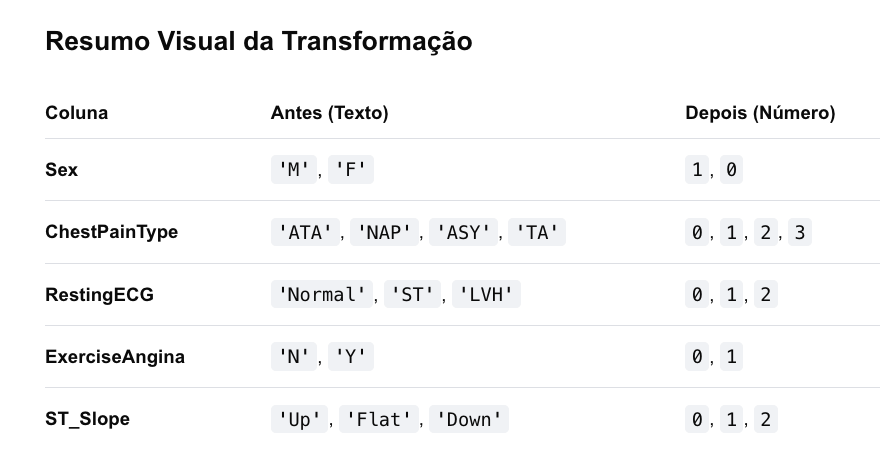

In [ ]:
#================================================================================================================
# Cópia do dataset original (boa prática: preservar os dados brutos)
#Cria uma cópia exata da tabela original dataset e salva em uma nova variável chamada df
#(abreviação padrão para DataFrame).

df = dataset.copy()

#================================================================================================================

# Mapeamentos explícitos variáveis categóricas-Mapeamento variáveis categóricas p/numéricas

df['Sex'] = df['Sex'].map({'M': 1, 'F': 0})
df['ChestPainType'] = df['ChestPainType'].map({'ATA': 0, 'NAP': 1, 'ASY': 2, 'TA': 3})
df['RestingECG'] = df['RestingECG'].map({'Normal': 0, 'ST': 1, 'LVH': 2})
df['ExerciseAngina'] = df['ExerciseAngina'].map({'N': 0, 'Y': 1})
df['ST_Slope'] = df['ST_Slope'].map({'Up': 0, 'Flat': 1, 'Down': 2})

#================================================================================================================
# Conferência: nenhum valor nulo pode restar após o mapeamento
print("Valores nulos por coluna após a codificação:")
print(df.isnull().sum())
df.head()

Valores nulos por coluna após a codificação:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,1,0,140,289,0,0,172,0,0.0,0,0
1,49,0,1,160,180,0,0,156,0,1.0,1,1
2,37,1,0,130,283,0,1,98,0,0.0,0,0
3,48,0,2,138,214,0,0,108,1,1.5,1,1
4,54,1,1,150,195,0,0,122,0,0.0,0,0


**4. Célula de Código -   Pré-processamento Holdout**

Esse blco 4 de código,  prepara o ambiente de "estudo e prova" para a Inteligência Artificial. O objetivo principal dele é separar as perguntas das respostas e dividir os pacientes em dois grupos (um para a máquina estudar e outro para fazer a prova final), garantindo que ambos os grupos tenham exatamente a mesma proporção de pessoas doentes e saudáveis.

### 4.2 Separação em treino e teste (Holdout 80/20) -  Codificação e Divisão (80/20)

Separamos **20% dos dados para teste** (a "prova final", que o modelo só verá na avaliação) e **80% para treino**. Usamos:

* `stratify=y` — garante que a proporção das classes seja mantida nas duas partições;
* `random_state=7` (semente fixa) — garante a **reprodutibilidade** do experimento;
* **Validação cruzada estratificada com 10 partições** (*10-fold StratifiedKFold*) sobre os dados de treino, para comparar os modelos de forma robusta sem contaminar a base de teste.
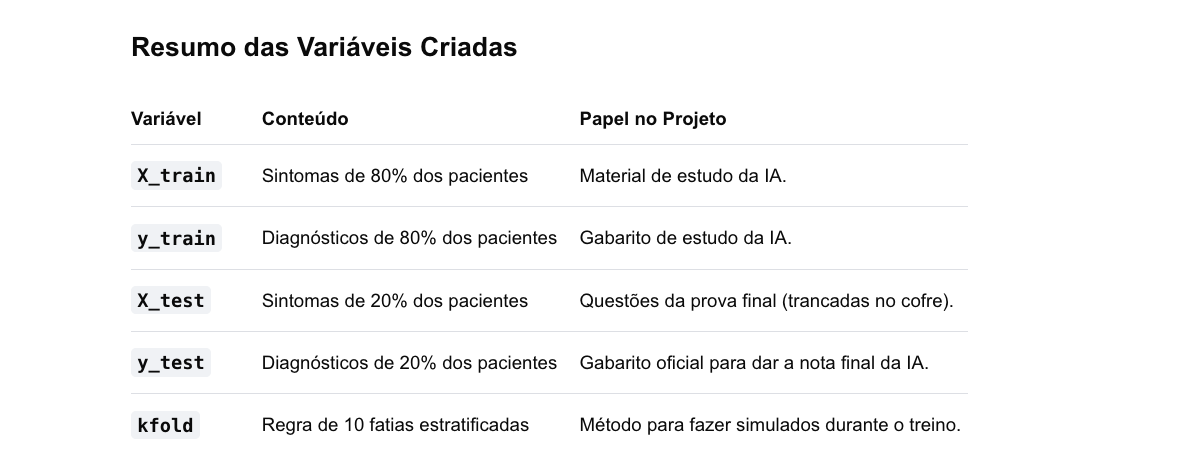

In [ ]:
# Separação entre atributos previsores (X) e classe alvo (y)
# Assim - Separando Perguntas (X) e Respostas (y)

#================================================================================================================
# pega a tabela completa df e remove a coluna 'HeartDisease' (axis=1 indica que estamos
# removendo uma coluna, e não uma linha).
# O .values transforma a tabela numa matriz numérica pura (formato NumPy).
# O X maiúsculo guarda todos os sintomas e exames (as "perguntas").

X = df.drop('HeartDisease', axis=1).values

# pega apenas a coluna 'HeartDisease' e transforma em uma lista numérica pura.
# O y minúsculo guarda o diagnóstico real (as "respostas" ou o alvo).

y = df['HeartDisease'].values

#================================================================================================================
# Holdout: 80% treino, 20% teste, com estratificação e semente fixa
# define uma "semente" aleatória fixa (número 7). Como o computador sorteia quem vai para o treino e quem vai para o teste,
# travar a semente garante que o sorteio seja sempre igual toda vez que você rodar o código. Isso permite reproduzir os resultados.

seed = 7

# (train_test_split): Essa função embaralha e fatia os dados em 4 partes: perguntas de treino (X_train),
# perguntas de teste (X_test), respostas de treino (y_train) e respostas de teste (y_test).

# test_size=0.20: Reserva 20% dos pacientes para o teste (prova final) e deixa 80% para o treino (estudo), random_state=seed: Aplica a semente 7 para travar a aleatoriedade.
# stratify=y: Garante a estratificação. Se a base original tem 55% de pessoas doentes, tanto o grupo de treino quanto o de teste terão exatamente 55% de pessoas doentes,
# evitando que um grupo fique só com pessoas saudáveis por azar no sorteio.


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed, stratify=y
)
#================================================================================================================
# Validação cruzada estratificada com 10 folds - Configurando os "Simulados"

# Define que os dados de treino serão divididos em 10 fatias iguais.
num_particoes = 10
# cria a regra de validação cruzada. -n_splits=num_particoes: configura as 10 divisões, -shuffle=True: Embaralha os pacientes antes de cortar nas 10 fatias para evitar vícios de ordem,
#-random_state=seed: Usa a mesma semente 7 para manter a reprodutibilidade.


kfold = StratifiedKFold(n_splits=num_particoes, shuffle=True, random_state=seed)
#================================================================================================================
#  Conferindo o Resultado da Divisão
# shape[0] conta quantas linhas (pacientes) ficaram no grupo de treino (80%) e quantas ficaram no grupo de teste (20%).
# Linha 2: Como y só tem números 0 (saudável) e 1 (doente), calcular a média (.mean()) revela exatamente a porcentagem de casos positivos (1).
# O :.3f mostra 3 casas decimais. Você verá dois números praticamente idênticos (ex: 0.553 no treino e 0.554 no teste), provando que o stratify=y funcionou perfeitamente.

print(f"Treino: {X_train.shape[0]} pacientes | Teste: {X_test.shape[0]} pacientes")
print(f"Proporção da classe 1 no treino: {y_train.mean():.3f} | no teste: {y_test.mean():.3f}")

Treino: 734 pacientes | Teste: 184 pacientes
Proporção da classe 1 no treino: 0.553 | no teste: 0.554


## 5. Célula de Código - Modelagem e Comparação de Algoritmos

Vamos Colocar para competir os **4 algoritmos clássicos** estudados na disciplina, mais o Random Forest como *ensemble* adicional:

* **KNN (K-Nearest Neighbors):** classifica pelo voto dos "k" vizinhos mais próximos;
* **CART (Árvore de Classificação):** cria regras de decisão hierárquicas;
* **Naive Bayes (GaussianNB):** calcula probabilidades pelo Teorema de Bayes;
* **SVM (Support Vector Machine):** traça fronteiras de separação ótimas entre as classes;
* **Random Forest:** comitê de árvores de decisão (*bagging*).

Cada algoritmo é avaliado em **3 cenários de escala de dados**, usando **Pipelines** (que aplicam o scaler apenas nos folds de treino, evitando *data leakage*):

1. **Originais** (sem transformação);
2. **Padronizados** (`StandardScaler`: média 0 e desvio padrão 1);
3. **Normalizados** (`MinMaxScaler`: valores entre 0 e 1).

O objetivo principal desse bloco é colocar 5 algoritmos diferentes para competir em 3 cenários de preparação de dados (totalizando 15 combinações), avaliando qual deles acerta mais diagnósticos sem vazar informações da prova.



In [ ]:
# Travando a aleatoriedade e listando os competidores
np.random.seed(seed)

#================================================================================================================
# Listando os Modelos competidores
#================================================================================================================
# Algoritmos base
modelos = [
    ('KNN', KNeighborsClassifier()),
    ('CART', DecisionTreeClassifier()),
    ('NB', GaussianNB()),
    ('SVM', SVC()),
    ('RF', RandomForestClassifier())
]

#================================================================================================================
# Montando as 15 "Esteiras" (Pipelines)
#================================================================================================================


# pipelines Cria uma lista vazia que vai armazenar todas as 15 configurações de teste.

pipelines = []

#======================
# Cenários - esteiras
#======================

# Cenário A: dados originais
for nome, modelo in modelos:
    pipelines.append((f'Orig-{nome}', Pipeline([(nome, modelo)])))

# Cenário B: dados padronizados (StandardScaler)
for nome, modelo in modelos:
    pipelines.append((f'Pad-{nome}', Pipeline([('Scaler', StandardScaler()), (nome, modelo)])))

# Cenário C: dados normalizados (MinMaxScaler)
for nome, modelo in modelos:
    pipelines.append((f'Norm-{nome}', Pipeline([('Scaler', MinMaxScaler()), (nome, modelo)])))

#================================================================================================================
# Rodando os Teste e Exibindo o Placar
#================================================================================================================
# Execução da validação cruzada 10-fold para cada pipeline
resultados = []
nomes = []
for nome, model in pipelines:
    cv_results = cross_val_score(model, X_train, y_train, cv=kfold, scoring='accuracy')
    resultados.append(cv_results)
    nomes.append(nome)
    print(f"{nome:10s}: Média = {cv_results.mean():.4f} | Desvio Padrão = {cv_results.std():.4f}")

Orig-KNN  : Média = 0.7083 | Desvio Padrão = 0.0519
Orig-CART : Média = 0.7807 | Desvio Padrão = 0.0345
Orig-NB   : Média = 0.8475 | Desvio Padrão = 0.0429
Orig-SVM  : Média = 0.7303 | Desvio Padrão = 0.0355
Orig-RF   : Média = 0.8611 | Desvio Padrão = 0.0391
Pad-KNN   : Média = 0.8599 | Desvio Padrão = 0.0533
Pad-CART  : Média = 0.7875 | Desvio Padrão = 0.0372
Pad-NB    : Média = 0.8475 | Desvio Padrão = 0.0429
Pad-SVM   : Média = 0.8598 | Desvio Padrão = 0.0376
Pad-RF    : Média = 0.8570 | Desvio Padrão = 0.0375
Norm-KNN  : Média = 0.8435 | Desvio Padrão = 0.0460
Norm-CART : Média = 0.7848 | Desvio Padrão = 0.0367
Norm-NB   : Média = 0.8475 | Desvio Padrão = 0.0429
Norm-SVM  : Média = 0.8598 | Desvio Padrão = 0.0381
Norm-RF   : Média = 0.8502 | Desvio Padrão = 0.0302


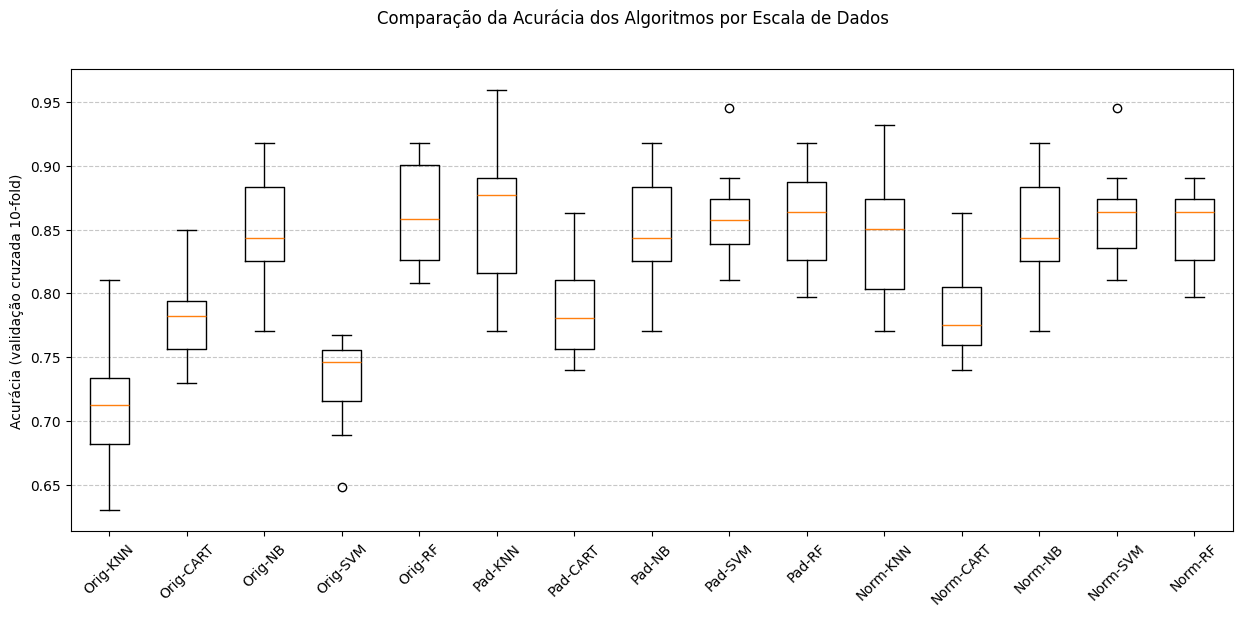

In [ ]:
# Boxplot comparativo da acurácia dos 15 experimentos

# Definindo o tamanho da imagem - cria uma figura em branco com 15 polegadas de largura por 6 de altura.
fig = plt.figure(figsize=(15, 6))

# Adicionando o título principal - escreve um título centralizado no topo da figura inteira. Isso deixa claro para qualquer leitor qual é o tema da comparação visual.
fig.suptitle('Comparação da Acurácia dos Algoritmos por Escala de Dados')

#  Criando a área dos eixos - cria uma área de plotagem única dentro da figura (1 linha, 1 coluna, posição 1).
# Guardar isso na variável ax permite personalizar os textos e rótulos dos eixos com precisão nas linhas seguintes.
ax = fig.add_subplot(111)

# Desenhando as caixas -  Esta função recebe a lista resultados (que contém 15 listas com 10 notas cada) e desenha automaticamente os 15 diagramas de caixa.
# É o comando central que calcula medianas, quartis e limites de variação.
plt.boxplot(resultados)

# Nomeando cada experimento - Rótulos inclinados. Substitui os números padrão (1, 2, 3...) do eixo horizontal pelos nomes reais guardados na lista nomes (como Orig-KNN e Pad-SVM).
# O parâmetro rotation=45 inclina os textos em 45 graus para que uma palavra não bata na outra.
ax.set_xticklabels(nomes, rotation=45)

#  Identificando o eixo vertical - • Escreve no eixo vertical (Y) o que os números de 0.65 a 0.95 significam.
# Isso informa que a altura de cada caixa representa a porcentagem de acertos nos 10 simulados.
plt.ylabel('Acurácia (validação cruzada 10-fold)')

# Adicionando linhas de grad -Guias visuais. Desenha linhas tracejadas (linestyle='--') apenas na direção horizontal (axis='y') com leve transparência (alpha=0.7).
# Essas linhas ajudam o olho humano a comparar exatamente qual caixa está mais alta em relação aos valores da esquerda.
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Exibindo o gráfico
plt.show()


*Leitura dos resultados da linha de base:**

* Os algoritmos baseados em **distância (KNN e SVM)** melhoram drasticamente com o escalonamento: o KNN salta de ~71% (original) para ~86% (padronizado) — sem escala, variáveis de magnitude alta como `Cholesterol` dominam o cálculo de distância e "abafam" variáveis importantes como `Oldpeak`;
* **Naive Bayes** e **CART** são indiferentes à escala (como esperado, pois não usam distâncias);
* **Random Forest**, **KNN padronizado** e **SVM padronizado** despontam como os melhores candidatos (~86%) e seguem para a etapa de otimização.

# 6. Otimização de Hiperparâmetros (GridSearchCV)

Aplicamos o `GridSearchCV` nos três melhores candidatos, sempre dentro de Pipelines com `StandardScaler` e avaliados com a mesma validação cruzada 10-fold:

* **SVM:** custo de regularização `C` e tipo de `kernel`;
* **Random Forest:** número de árvores (`n_estimators`) e profundidade máxima (`max_depth`);
* **KNN:** número de vizinhos (`n_neighbors`, valores ímpares para evitar empates) e métrica de distância (`euclidean`, `manhattan`, `minkowski`).

In [ ]:
# Travando a aleatoriedade - Fixa a semente aleatória global para garantir que, se você rodar esse código amanhã, os resultados sejam idênticos aos de hoje.
np.random.seed(seed)

#================================================================================================================
# Otimização do SVM
#================================================================================================================
# • Monta a esteira de 2 passos: padroniza os dados (Scaler) e entrega ao modelo (SVM).
pipeline_svm = Pipeline([('Scaler', StandardScaler()), ('SVM', SVC())])

# Cria o cardápio de testes (3 valores de C × 2 tipos de kernel = 6 combinações).
param_grid_svm = {
    'SVM__C': [0.1, 1, 10],
    'SVM__kernel': ['rbf', 'linear']
}

# Configura o robô testador para avaliar a esteira (estimator), testando o cardápio (param_grid), medindo acertos (scoring='accuracy') nos 10 simulados (cv=kfold).
grid_svm = GridSearchCV(estimator=pipeline_svm, param_grid=param_grid_svm, scoring='accuracy', cv=kfold)

# Manda o robô trabalhar! Ele treina o modelo 60 vezes (6 combinações × 10 simulados) usando os dados de estudo.
grid_svm.fit(X_train, y_train)
• Mostra a maior nota média alcançada (.best_score_) e qual foi a combinação campeã de botões (.best_params_).

print(f"Melhor SVM          : {grid_svm.best_score_:.4f} usando {grid_svm.best_params_}")

#================================================================================================================
# Otimização do Random Forest
#================================================================================================================

# RandomForestClassifier(random_state=seed) recebe a semente interna para que as árvores cresçam sempre da mesma forma.
pipeline_rf = Pipeline([('Scaler', StandardScaler()), ('RF', RandomForestClassifier(random_state=seed))])

# Testa florestas com 50, 100 ou 200 árvores, combinadas com profundidade ilimitada (None), máxima de 5 perguntas ou máxima de 10 perguntas (3 × 3 = 9 combinações,
# totalizando 90 treinos).
param_grid_rf = {
    'RF__n_estimators': [50, 100, 200],
    'RF__max_depth': [None, 5, 10]
}
grid_rf = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid_rf, scoring='accuracy', cv=kfold)

# O .fit() roda os testes e o print() exibe a melhor nota e a melhor configuração da floresta.

grid_rf.fit(X_train, y_train)
print(f"Melhor Random Forest: {grid_rf.best_score_:.4f} usando {grid_rf.best_params_}")

#================================================================================================================
# Otimização do KNN
#================================================================================================================
# esta grupos de 3, 5, 7, 9 ou 11 vizinhos mais próximos, combinados com 3 fórmulas geométricas diferentes de distância
# (euclidean, manhattan, minkowski). São 5 × 3 = 15 combinações (150 treinos).
pipeline_knn = Pipeline([('Scaler', StandardScaler()), ('KNN', KNeighborsClassifier())])
param_grid_knn = {
    'KNN__n_neighbors': [3, 5, 7, 9, 11],
    'KNN__metric': ['euclidean', 'manhattan', 'minkowski']
}
grid_knn = GridSearchCV(estimator=pipeline_knn, param_grid=param_grid_knn, scoring='accuracy', cv=kfold)

# O .fit() executa todas as combinações e o print() revela qual quantidade de vizinhos e qual régua matemática acertaram mais diagnósticos.

grid_knn.fit(X_train, y_train)
print(f"Melhor KNN          : {grid_knn.best_score_:.4f} usando {grid_knn.best_params_}")

Melhor SVM          : 0.8598 usando {'SVM__C': 1, 'SVM__kernel': 'rbf'}
Melhor Random Forest: 0.8666 usando {'RF__max_depth': 5, 'RF__n_estimators': 200}
Melhor KNN          : 0.8720 usando {'KNN__metric': 'manhattan', 'KNN__n_neighbors': 7}


## 7. Avaliação Final na Base de Teste

Selecionamos automaticamente o **modelo campeão** (maior acurácia média na validação cruzada) e o submetemos à "prova final": os **20% de dados de teste que ele nunca viu**. Além da acurácia, reportamos o **recall** (sensibilidade) — métrica crítica em triagem médica, pois mede a capacidade de **não deixar passar pacientes doentes** (falsos negativos são o erro mais grave neste contexto).

In [ ]:
# Seleção automática do campeão pela validação cruzada

#================================================================================================================
# Escolhendo o Vencedor Automaticamente

# Cria um dicionário reunindo os três robôs otimizados na etapa anterior.
candidatos = {'SVM': grid_svm, 'Random Forest': grid_rf, 'KNN': grid_knn}

# A função max() compara os três candidatos. O argumento key=lambda n:
# candidatos[n].best_score_ ensina o Python a olhar especificamente para a maior nota média (.best_score_) de cada um.
# Ele descobre que o KNN venceu com 0.8720 (87,20%).
nome_campeao = max(candidatos, key=lambda n: candidatos[n].best_score_)

# Extrai de dentro do grid_knn a esteira completa já treinada com os melhores hiperparâmetros encontrados.
modelo_campeao = candidatos[nome_campeao].best_estimator_

# Exibe o nome do vencedor (KNN) e sua nota nos simulados (0.8720). O \n no final pula uma linha em branco para organizar o texto.
print(f"Modelo campeão: {nome_campeao} (acurácia CV = {candidatos[nome_campeao].best_score_:.4f})\n")

#================================================================================================================

# Avaliação na base de teste (dados nunca vistos)

# Pega os sintomas dos 184 pacientes inéditos (X_test) e pede para o KNN dar o diagnóstico (0 ou 1) para cada um.
predicoes = modelo_campeao.predict(X_test)

# Compara o gabarito oficial (y_test) com os palpites da IA (predicoes) e calcula a porcentagem geral de acertos.
acuracia_teste = accuracy_score(y_test, predicoes)

# Calcula a sensibilidade, ou seja, de todos os pacientes que realmente estavam doentes no teste, quantos por cento a IA conseguiu detectar.
recall_teste = recall_score(y_test, predicoes)

#Calcula a média harmônica entre a precisão e o recall, servindo como um indicador de equilíbrio geral do modelo.
f1_teste = f1_score(y_test, predicoes)
#================================================================================================================
# Exibindo o Boletim Detalhado

# Imprimem as três métricas principais formatadas com 4 casas decimais (:.4f). Na acurácia, multiplica por 100 para mostrar em porcentagem (88.04%).
print(f"Acurácia na base de teste : {acuracia_teste:.4f} ({acuracia_teste*100:.2f}%)")
print(f"Recall (sensibilidade)    : {recall_teste:.4f}")
print(f"F1-Score                  : {f1_teste:.4f}\n")

# Gera uma tabela completa separando o desempenho do modelo para pacientes saudáveis (Normal (0)) e doentes (Doença (1)).
print("Relatório de Classificação:")
print(classification_report(y_test, predicoes, target_names=['Normal (0)', 'Doença (1)']))

Modelo campeão: KNN (acurácia CV = 0.8720)

Acurácia na base de teste : 0.8804 (88.04%)
Recall (sensibilidade)    : 0.9118
F1-Score                  : 0.8942

Relatório de Classificação:
              precision    recall  f1-score   support

  Normal (0)       0.88      0.84      0.86        82
  Doença (1)       0.88      0.91      0.89       102

    accuracy                           0.88       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.88      0.88      0.88       184



# Matriz de Confusão
Este trecho de código gera uma Matriz de Confusão, que é a melhor ferramenta visual para abrir a "caixa-preta" dos acertos e erros do modelo. O objetivo principal desse bloco é cruzar o diagnóstico real dos 184 pacientes de teste com o palpite dado pelo KNN, mostrando exatamente quantos pacientes foram classificados corretamente e onde o modelo se confundiu.

Explicação Conceitual: Como ler a Matriz de Confusão da imagem?

Para entender os 4 quadrados azuis do gráfico, compare sempre a linha da esquerda (Classe Real, que é a verdade médica) com a coluna de baixo (Classe Predita, que é o chute da Inteligência Artificial):

## Diagonal Principal (Quadrados escuros — Os Acertos):

• **69 (Verdadeiro Negativo)**: O paciente era saudável (Normal (0)) e a IA acertou dizendo que ele era saudável (Normal (0)).
•** 93 (Verdadeiro Positivo)**: O paciente estava doente (Doença (1)) e a IA acertou dizendo que ele estava doente (Doença (1)).

## Diagonal Secundária (Quadrados claros — Os Erros):
• **13 (Falso Positivo — Alarme Falso)**: O paciente era saudável, mas a IA achou que ele tinha doença cardíaca. Na prática clínica, ele passaria por exames extras para tirar a dúvida.

• **9 (Falso Negativo — O Erro Crítico)**: O paciente realmente tinha doença cardíaca, mas a IA o liberou dizendo que estava normal. Como vimos antes, manter esse número baixo (apenas 9 em 102 doentes) é o motivo do alto Recall de 91,18%.





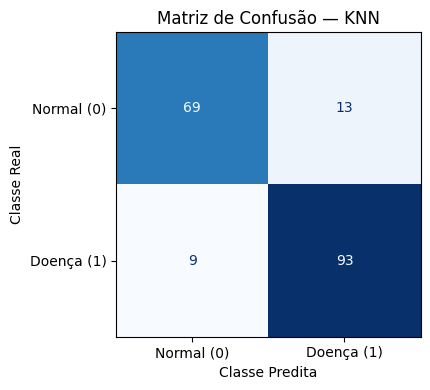

In [ ]:
# Matriz de confusão
# • Prepara uma área de desenho compacta com 5 polegadas de largura por 4 de altura (figsize=(5, 4)), separando a imagem (fig) dos eixos (ax).
fig, ax = plt.subplots(figsize=(5, 4))

# Função matemática do Scikit-Learn que conta os 4 cenários (69, 13, 9 e 93) comparando o gabarito (y_test) com os palpites (predicoes).
ConfusionMatrixDisplay(confusion_matrix(y_test, predicoes),
                       # Transforma essa contagem num objeto visual e troca os números 0 e 1 pelos nomes claros 'Normal (0)' e 'Doença (1)'.
                       #• Desenha os quadrados dentro dos eixos criados antes (ax=ax), pinta usando tons de azul (cmap='Blues', onde números maiores ficam mais escuros) e esconde a barra lateral de escala de cores (colorbar=False) para deixar o visual mais limpo.

                       display_labels=['Normal (0)', 'Doença (1)']).plot(ax=ax, cmap='Blues', colorbar=False)

# Escreve o título no topo inserindo dinamicamente o nome do modelo vencedor (KNN).
ax.set_title(f'Matriz de Confusão — {nome_campeao}')

# • Traduzem para o português os rótulos padrão do Scikit-Learn, deixando claro que a horizontal mostra a previsão da IA e a vertical mostra a realidade.
ax.set_xlabel('Classe Predita')
ax.set_ylabel('Classe Real')

# Ajusta automaticamente as margens internas para garantir que nenhum texto ou título fique cortado nas bordas da imagem.
plt.tight_layout()

# plt.show(): Renderiza o gráfico finalizado na tela.
plt.show()

### 8. Exportação do Modelo e do Golden Dataset

Exportamos três arquivos que serão embarcados na aplicação full stack:

1. **`modelo_cardiaco_pipeline.pkl`** — o pipeline campeão completo (scaler + classificador), serializado com `pickle`. A API Flask fará a carga deste arquivo e o usará para as predições;
2. **`X_test_cardiaco.csv`** e **`y_test_cardiaco.csv`** — o *golden dataset* (20% de teste), usado pelos **testes automatizados com PyTest** para garantir que o modelo implantado atenda aos requisitos mínimos de desempenho.

> No Google Colab, os arquivos aparecem no painel **Arquivos** (ícone de pasta à esquerda), de onde podem ser baixados.

In [ ]:
# Exportação do pipeline completo do modelo campeão
with open('modelo_cardiaco_pipeline.pkl', 'wb') as file:
    pickle.dump(modelo_campeao, file)

# Exportação do golden dataset (base de teste) para os testes automatizados
colunas_features = df.drop('HeartDisease', axis=1).columns
pd.DataFrame(X_test, columns=colunas_features).to_csv('X_test_cardiaco.csv', index=False)
pd.DataFrame(y_test, columns=['HeartDisease']).to_csv('y_test_cardiaco.csv', index=False)

print("Arquivos exportados com sucesso:")
print(" - modelo_cardiaco_pipeline.pkl")
print(" - X_test_cardiaco.csv")
print(" - y_test_cardiaco.csv")

Arquivos exportados com sucesso:
 - modelo_cardiaco_pipeline.pkl
 - X_test_cardiaco.csv
 - y_test_cardiaco.csv


# 9. Análise dos Resultados

**Principais achados do experimento:**

1. **O escalonamento dos dados foi decisivo.** O KNN saltou de ~71% (dados originais) para ~86% (padronizados), e o SVM de ~73% para ~86%. Isso confirma a teoria: algoritmos baseados em distância exigem que as variáveis estejam na mesma escala. Já CART e Naive Bayes mantiveram-se estáveis nos três cenários, como esperado.

2. **O modelo campeão foi o KNN padronizado** (k=7, distância Manhattan), com **~87% de acurácia na validação cruzada** e **~88% na base de teste** — a proximidade entre os dois valores indica que **não houve overfitting**: o modelo generaliza bem para dados nunca vistos.

3. **O recall de ~91% para a classe positiva é o resultado mais importante no contexto clínico:** de cada 100 pacientes realmente doentes, o modelo identifica corretamente cerca de 91. Em um sistema de **triagem** (que prioriza casos para avaliação médica, sem substituir o diagnóstico), minimizar falsos negativos é mais crítico do que evitar falsos alarmes.

**Pontos de atenção:**

* Os **falsos negativos remanescentes (~9%)** reforçam que o sistema deve ser usado como **apoio à triagem**, nunca como diagnóstico definitivo;
* Os **172 valores zerados em `Cholesterol`** (valores faltantes codificados como 0 na base original) introduzem ruído; um trabalho futuro poderia testar imputação pela mediana e comparar os resultados;
* O dataset (918 pacientes) é relativamente pequeno; bases maiores e mais diversas demograficamente aumentariam a confiança na generalização do modelo.

## 10. Reflexão sobre Segurança e Privacidade de Dados

Conforme as boas práticas da disciplina **Desenvolvimento de Software Seguro**, refletimos sobre a proteção dos dados neste problema:

* **Anonimização:** o dataset utilizado já é **anonimizado na origem** — não contém nomes, documentos, endereços ou qualquer identificador direto dos pacientes, apenas atributos clínicos agregados;
* **Minimização de dados (LGPD/GDPR):** a aplicação full stack deste MVP processa apenas os 11 atributos estritamente necessários à predição e **não persiste** os dados enviados pelo usuário;
* **Riscos de reidentificação:** mesmo dados anonimizados podem, em tese, ser cruzados com outras bases (ataques de *linkage*). Em um sistema real, técnicas como **k-anonimato**, **generalização** (ex.: faixas etárias em vez da idade exata) e **privacidade diferencial** deveriam ser consideradas;
* **Segurança da aplicação:** a API valida os dados de entrada via schemas (prevenindo injeção de dados malformados) e, em produção, deveria operar sob **HTTPS**, com autenticação e controle de acesso.

## 11. Conclusão

Este notebook percorreu o ciclo completo de construção de um modelo de machine learning para **classificação de risco de doença cardíaca**, seguindo a metodologia da disciplina: carga via URL pública, análise exploratória, pré-processamento, holdout estratificado 80/20, comparação de **KNN, Árvore de Classificação, Naive Bayes e SVM** (e Random Forest) em três cenários de escala com validação cruzada 10-fold e Pipelines, otimização com GridSearchCV, avaliação final e exportação do modelo.

O **KNN padronizado (k=7, Manhattan)** foi o campeão, atingindo **~88% de acurácia** e **~91% de recall** na base de teste — desempenho adequado para um sistema de **apoio à triagem** preventiva. O pipeline exportado (`modelo_cardiaco_pipeline.pkl`) será embarcado no back-end Flask da aplicação full stack, onde testes automatizados com PyTest garantirão continuamente que o modelo implantado atenda aos requisitos mínimos de desempenho estabelecidos (acurácia e recall), evitando a implantação de modelos degradados.

O MVP demonstra, assim, a integração entre **Ciência de Dados** e **Engenharia de Software**: um experimento científico reprodutível, documentado e versionado, que se transforma em um sistema inteligente funcional, testável e pronto para evolução.